# 1.0 - Análisis exploratorio

Exploración inicial del dataset *House Prices - Advanced Regression Techniques* (Kaggle).

- **Datos:** `data/raw/train.csv`, `data/raw/test.csv`
- **Diccionario de variables:** `data/raw/data_description.txt`
- **Variable objetivo:** `SalePrice`

## Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 100)

PROJ_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJ_ROOT / "data" / "raw"

## Carga de datos

In [2]:
train = pd.read_csv(RAW_DATA_DIR / "train.csv")
test = pd.read_csv(RAW_DATA_DIR / "test.csv")

print(f"train: {train.shape}")
print(f"test:  {test.shape}")

train: (1460, 81)
test:  (1459, 80)


In [3]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

## Variable objetivo: `SalePrice`

In [5]:
train["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

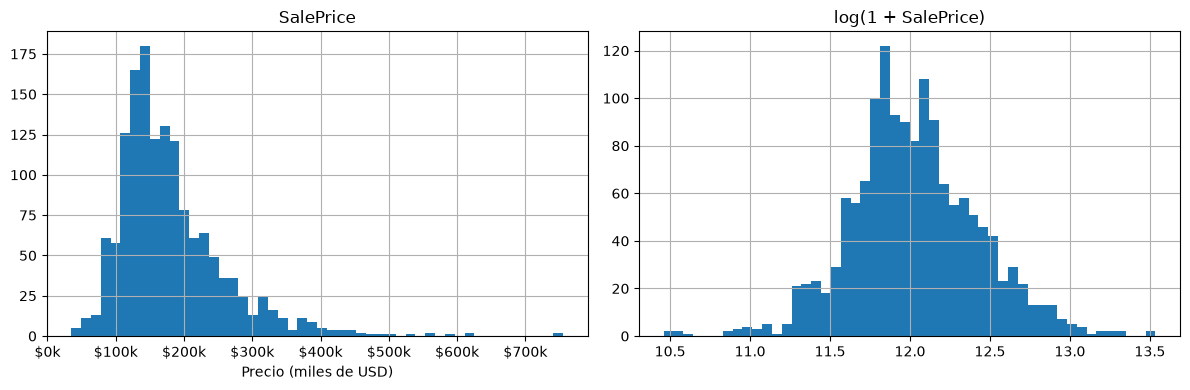

In [10]:
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train["SalePrice"].hist(bins=50, ax=axes[0])
axes[0].set_title("SalePrice")
axes[0].set_xlabel("Precio (miles de USD)")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x / 1000:,.0f}k"))
np.log1p(train["SalePrice"]).hist(bins=50, ax=axes[1])
axes[1].set_title("log(1 + SalePrice)")
plt.tight_layout()
plt.show()

## Valores faltantes

In [7]:
missing = train.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
(missing / len(train)).to_frame("pct_missing")

,pct_missing
PoolQC,0.995205
MiscFeature,0.963014
Alley,0.937671
Fence,0.807534
MasVnrType,0.597260
FireplaceQu,0.472603
LotFrontage,0.177397
GarageType,0.055479
GarageYrBlt,0.055479
GarageFinish,0.055479


## Variables numéricas vs. categóricas

In [8]:
num_cols = train.select_dtypes(include="number").columns.drop(["Id", "SalePrice"])
cat_cols = train.select_dtypes(exclude="number").columns

print(f"Numéricas:   {len(num_cols)}")
print(f"Categóricas: {len(cat_cols)}")

Numéricas:   36
Categóricas: 43


## Correlación con `SalePrice`

In [9]:
corr = train[num_cols.tolist() + ["SalePrice"]].corr()["SalePrice"].drop("SalePrice")
corr.sort_values(ascending=False).head(15)

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
LotFrontage     0.351799
Name: SalePrice, dtype: float64

## Variables discretas vs. continuas

Separa las variables numéricas en dos grupos según su número de valores distintos: las que tienen 15 o menos se consideran **discretas** (conteos, calificaciones, mes/año de venta) y el resto **continuas**. `PoolArea` se fuerza a continua porque es un área, aunque tenga pocos valores distintos (casi todas las casas tienen 0).

In [15]:
MAX_VALORES_DISCRETA = 15
forzar_continuas = ["PoolArea"]

n_unicos = train[num_cols].nunique()
discretas = [c for c in num_cols if n_unicos[c] <= MAX_VALORES_DISCRETA and c not in forzar_continuas]
continuas = [c for c in num_cols if c not in discretas]

print(f"Discretas ({len(discretas)}): {discretas}")
print(f"Continuas ({len(continuas)}): {continuas}")

Discretas (14): ['MSSubClass', 'OverallQual', 'OverallCond', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'MoSold', 'YrSold']
Continuas (22): ['LotFrontage', 'LotArea', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']


## Scatter plots: variables continuas vs. `SalePrice`

Grafica cada variable continua contra `SalePrice` para identificar relaciones lineales, no lineales u outliers. El título de cada gráfica incluye la correlación de Pearson con `SalePrice`, y al final se muestra un DataFrame con las correlaciones ordenadas de mayor a menor.

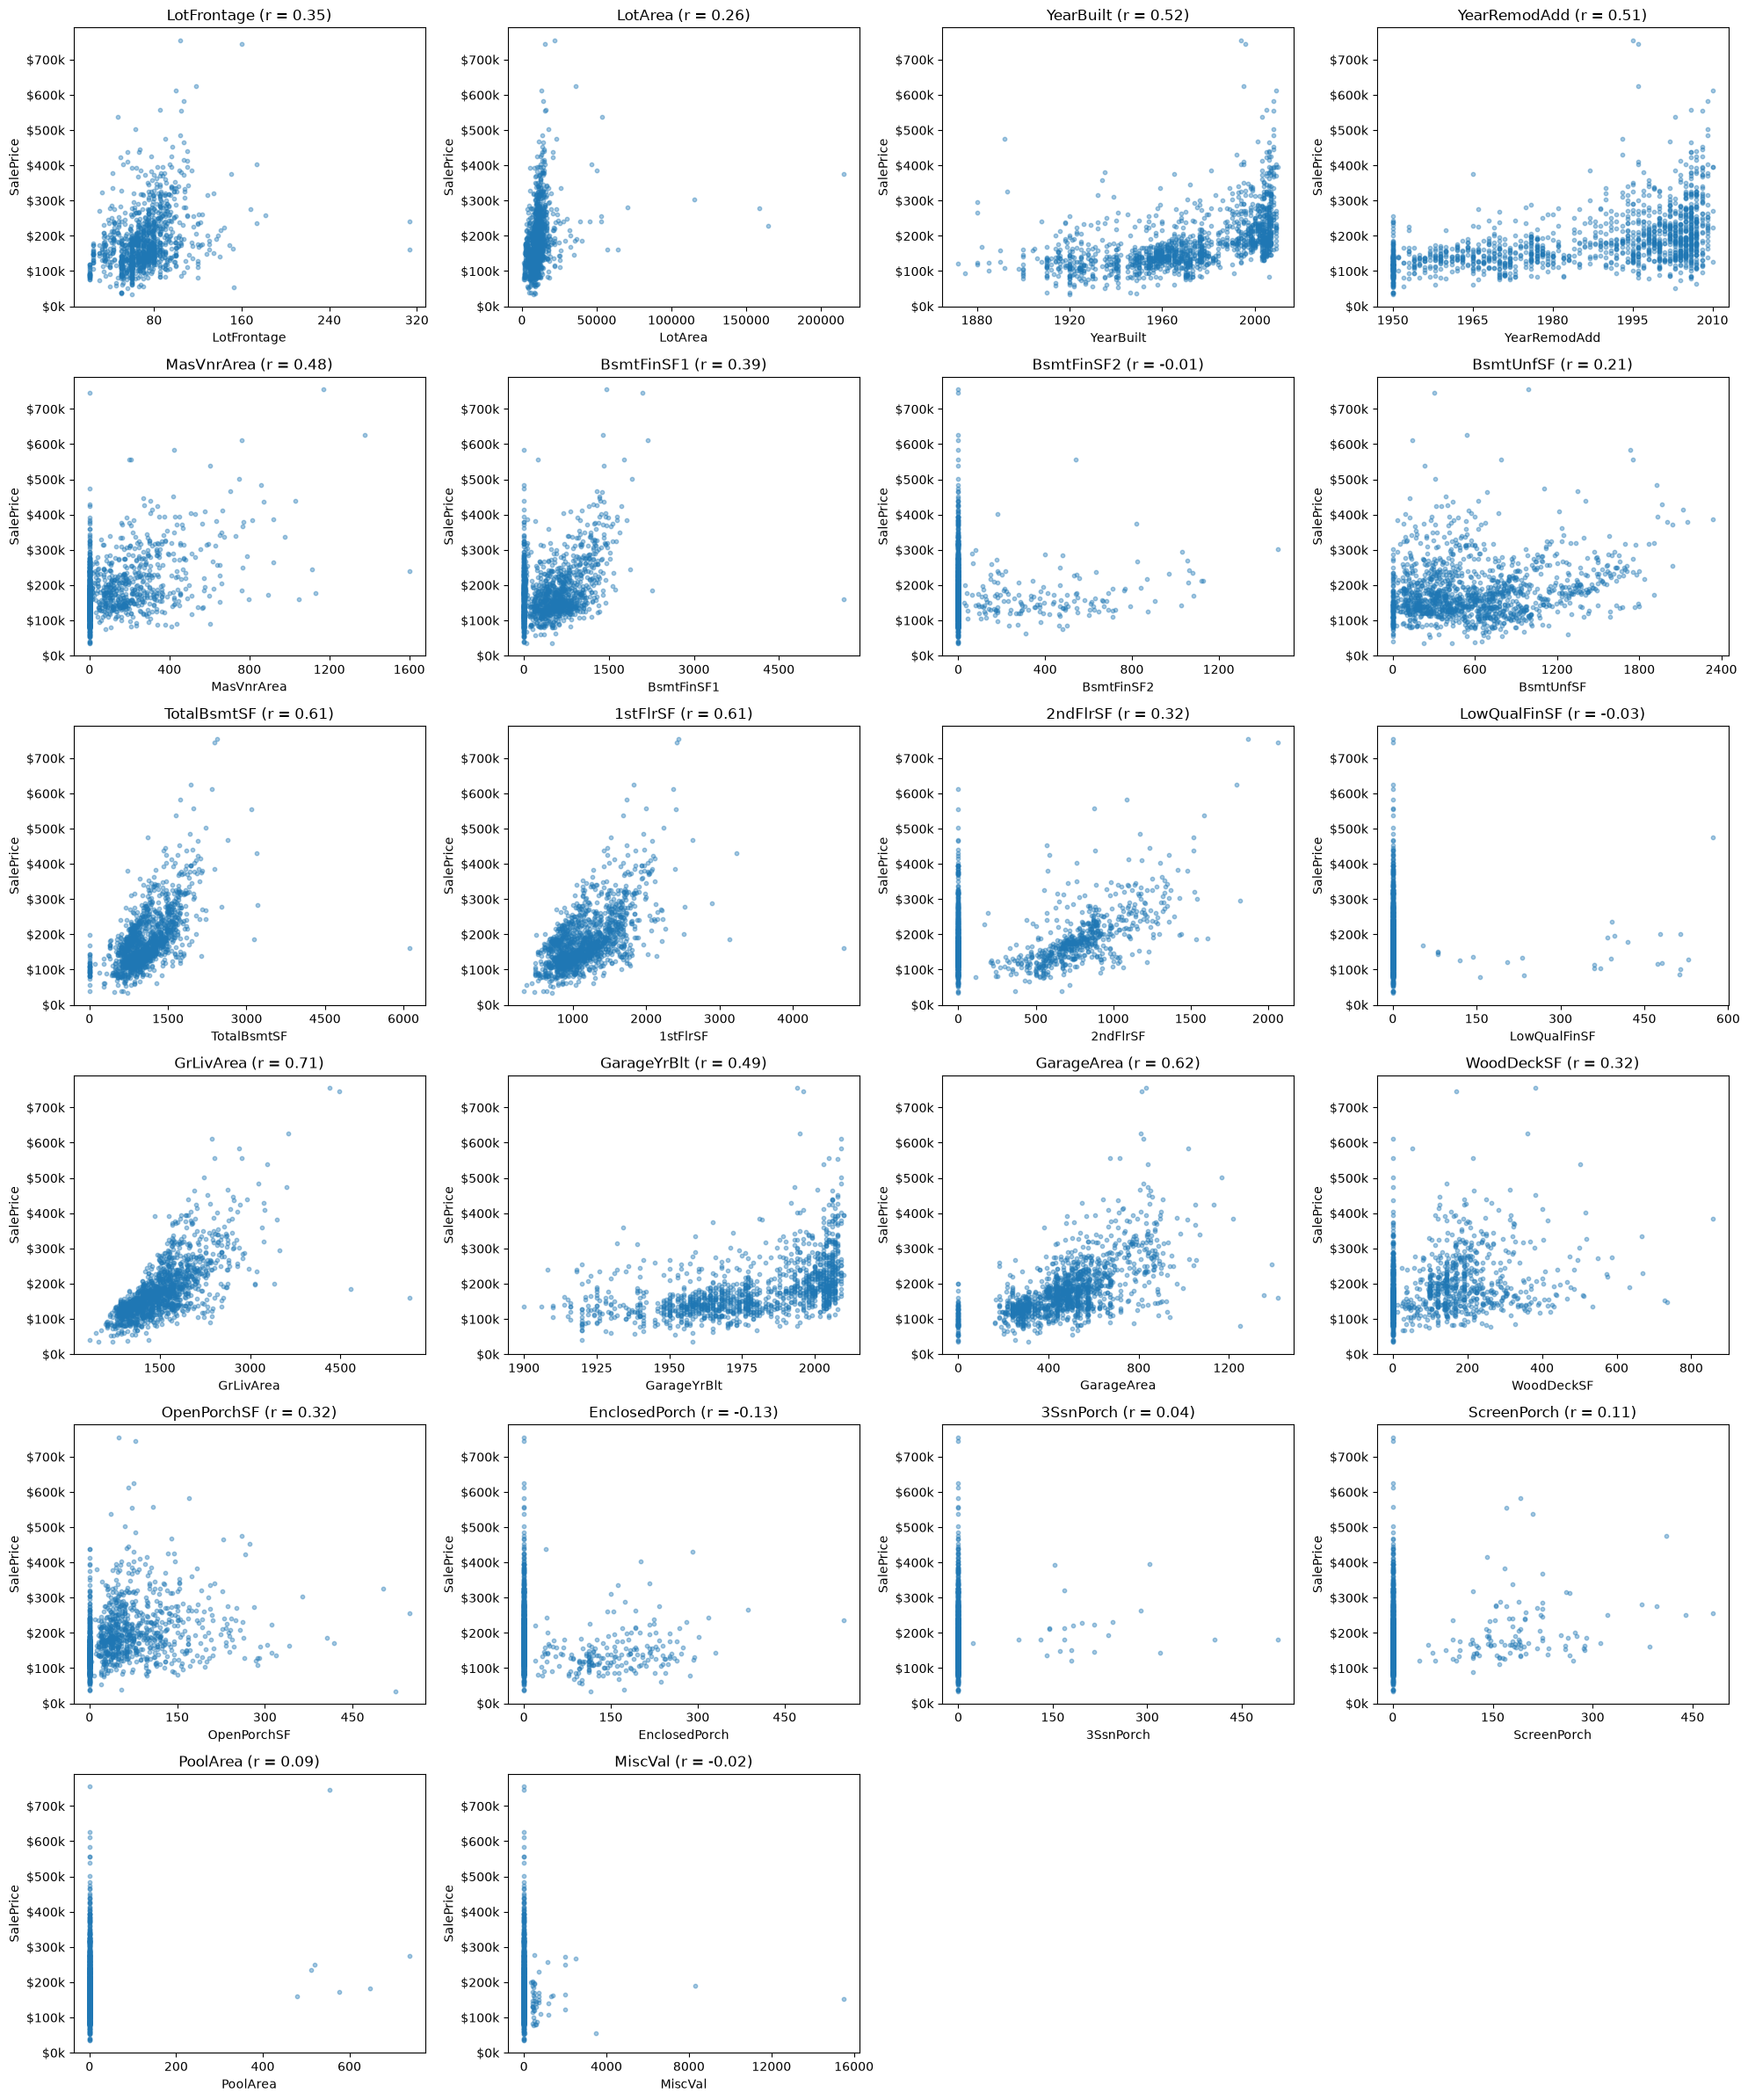

,correlacion
GrLivArea,0.708624
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
YearBuilt,0.522897
YearRemodAdd,0.507101
GarageYrBlt,0.486362
MasVnrArea,0.477493
BsmtFinSF1,0.386420
LotFrontage,0.351799


In [16]:
from matplotlib.ticker import MaxNLocator

n_cols = 4
n_rows = int(np.ceil(len(continuas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()

corr_continuas = {}
for ax, col in zip(axes, continuas):
    r = train[col].corr(train["SalePrice"])
    corr_continuas[col] = r
    ax.scatter(train[col], train["SalePrice"], alpha=0.4, s=10)
    ax.set_title(f"{col} (r = {r:.2f})")
    ax.set_xlabel(col)
    ax.set_ylabel("SalePrice")
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y / 1000:,.0f}k"))

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(continuas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

pd.Series(corr_continuas, name="correlacion").sort_values(ascending=False).to_frame()

## Boxplots: variables discretas vs. `SalePrice`

Para cada variable discreta dibuja un boxplot de `SalePrice` por cada valor de la variable, con los puntos individuales superpuestos (`stripplot` con *jitter*) para ver cuántas observaciones hay en cada categoría. El título incluye la correlación con `SalePrice`.

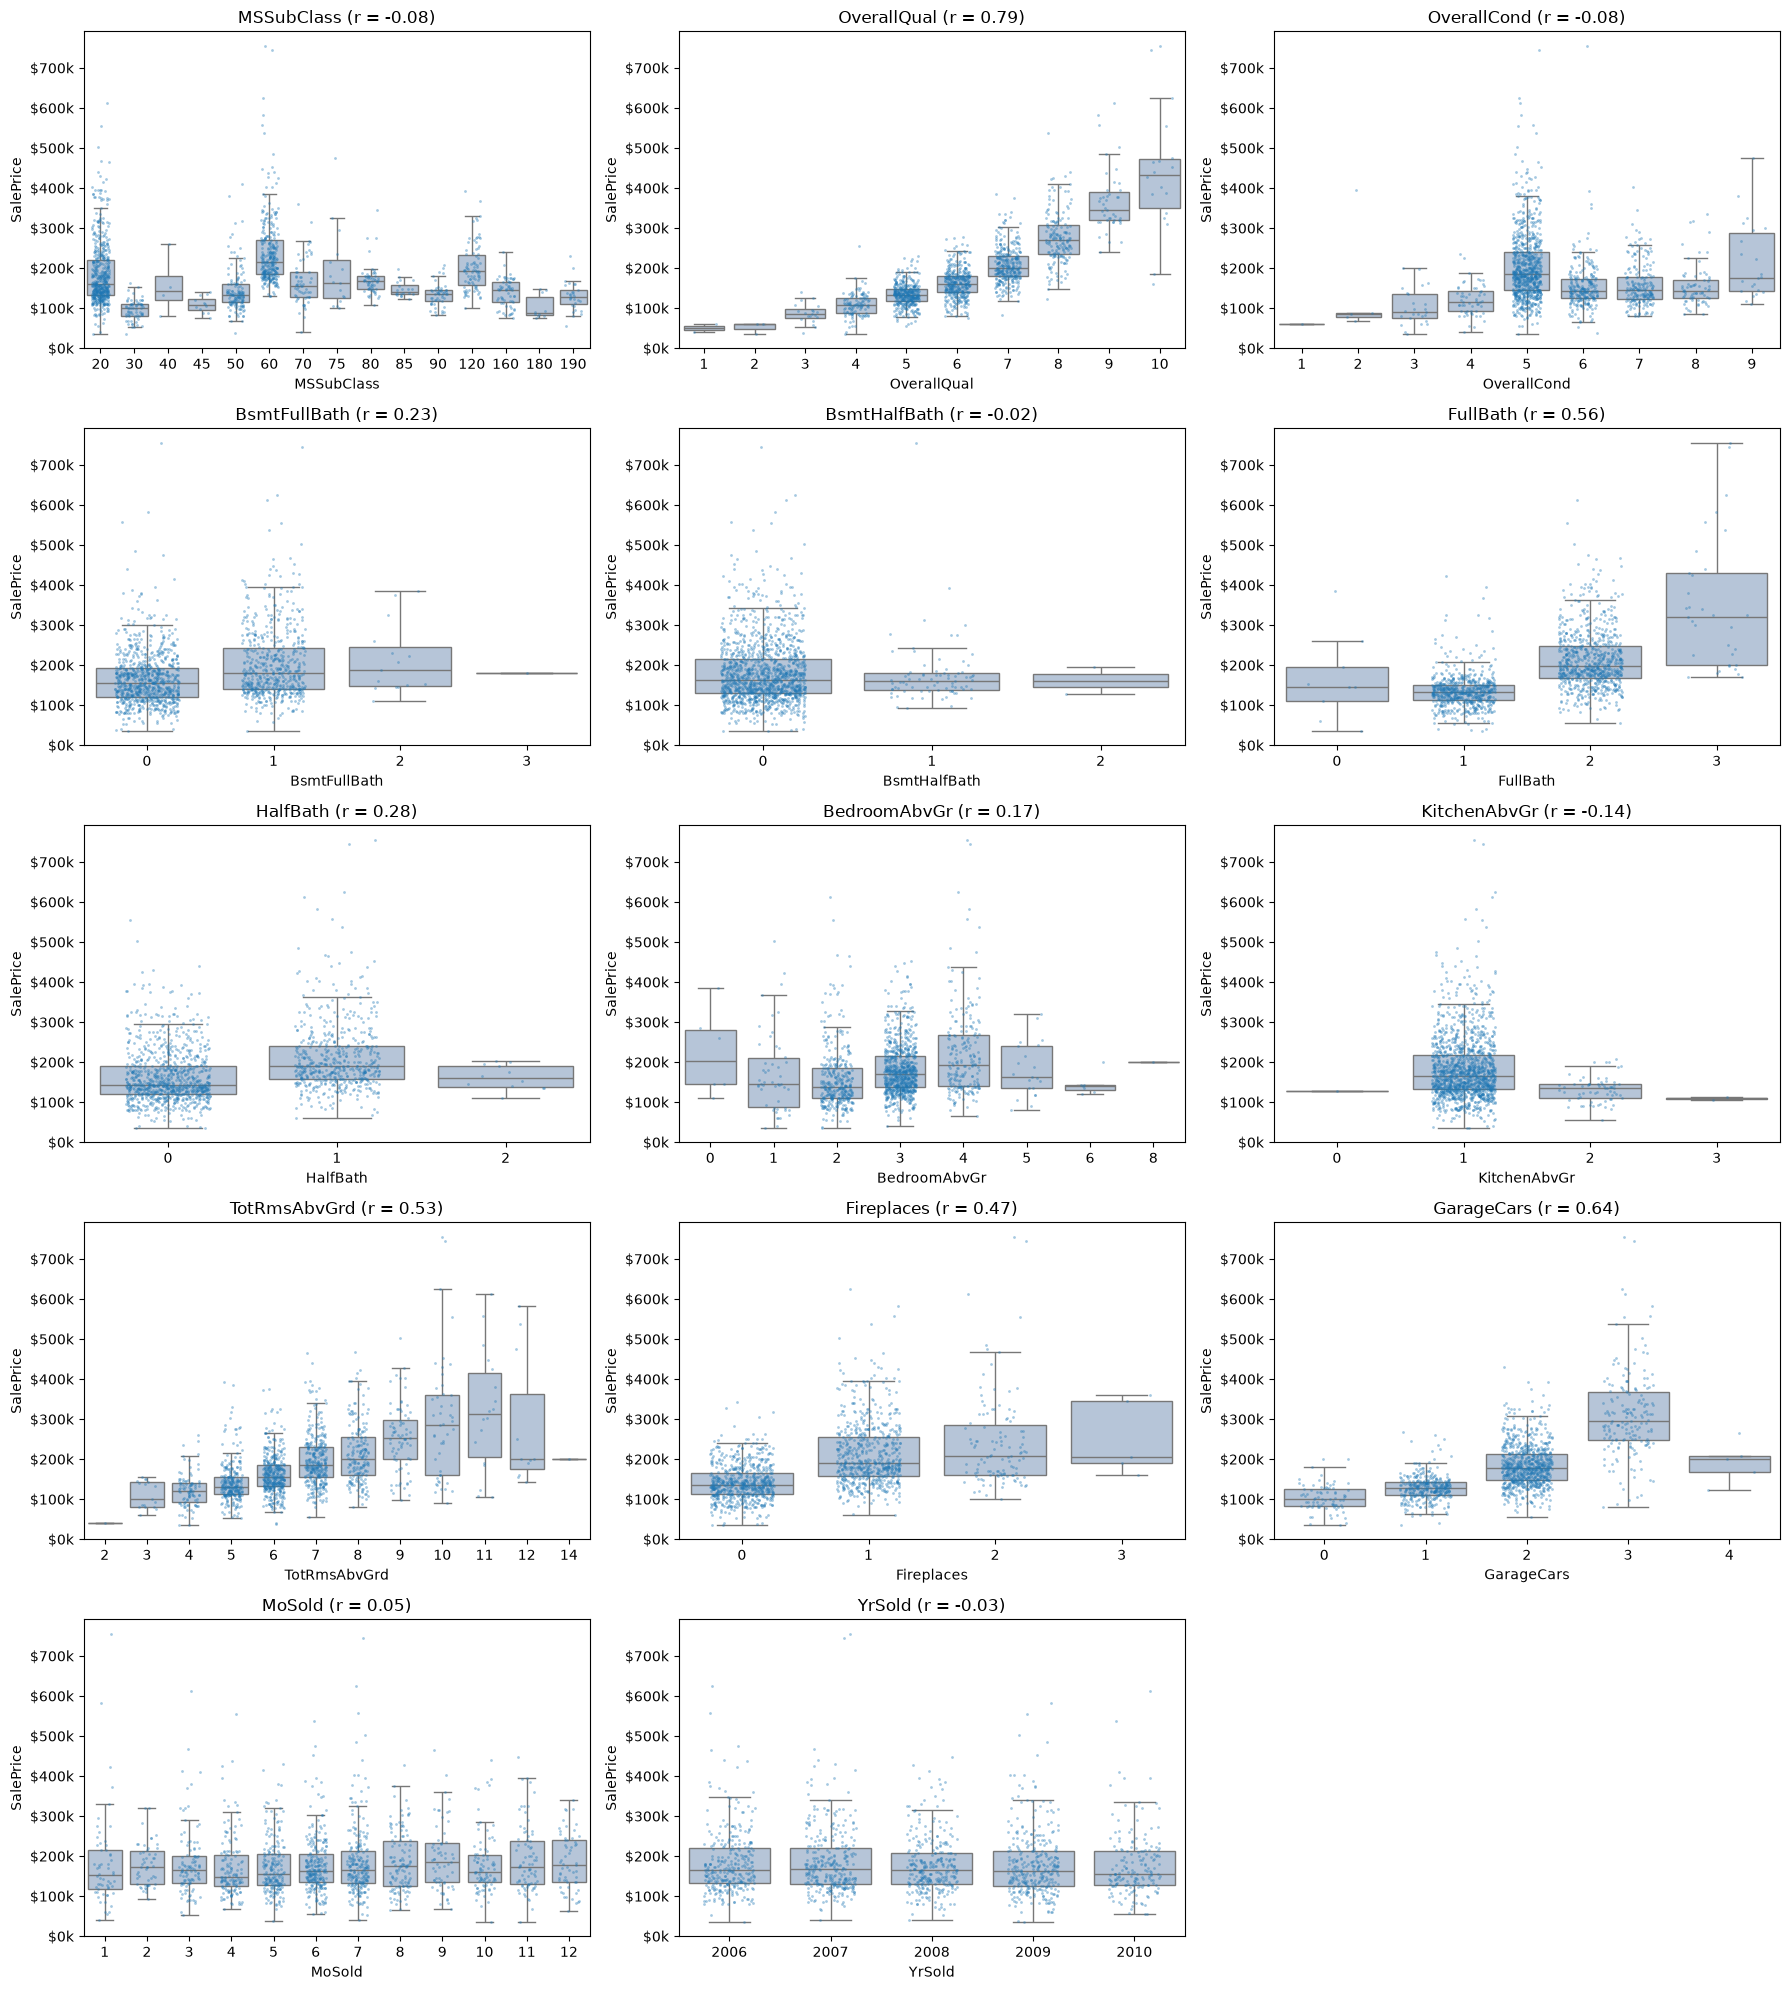

In [17]:
import seaborn as sns

n_cols = 3
n_rows = int(np.ceil(len(discretas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, discretas):
    r = train[col].corr(train["SalePrice"])
    sns.boxplot(data=train, x=col, y="SalePrice", ax=ax, color="lightsteelblue", showfliers=False)
    sns.stripplot(data=train, x=col, y="SalePrice", ax=ax, color="tab:blue", size=2, alpha=0.4, jitter=0.25)
    ax.set_title(f"{col} (r = {r:.2f})")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y / 1000:,.0f}k"))

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(discretas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## Boxplots: variables categóricas vs. `SalePrice`

Para cada variable categórica dibuja un boxplot de `SalePrice` por categoría, con los puntos individuales superpuestos. Las categorías se ordenan por mediana de precio y los valores faltantes se muestran como la categoría `"NA"` (en este dataset casi siempre significa "no tiene", p. ej. sin garage o sin sótano).

El título incluye la **razón de correlación η (eta)**, el equivalente a la correlación para una variable categórica contra una numérica:

$$\eta^2 = \frac{\sum_k n_k (\bar{y}_k - \bar{y})^2}{\sum_i (y_i - \bar{y})^2}$$

es decir, la fracción de la varianza de `SalePrice` que se explica por las diferencias entre las medias de cada categoría. Va de 0 (todas las categorías tienen el mismo precio promedio) a 1 (la categoría determina por completo el precio). Al final se muestra un DataFrame con η ordenado de mayor a menor.

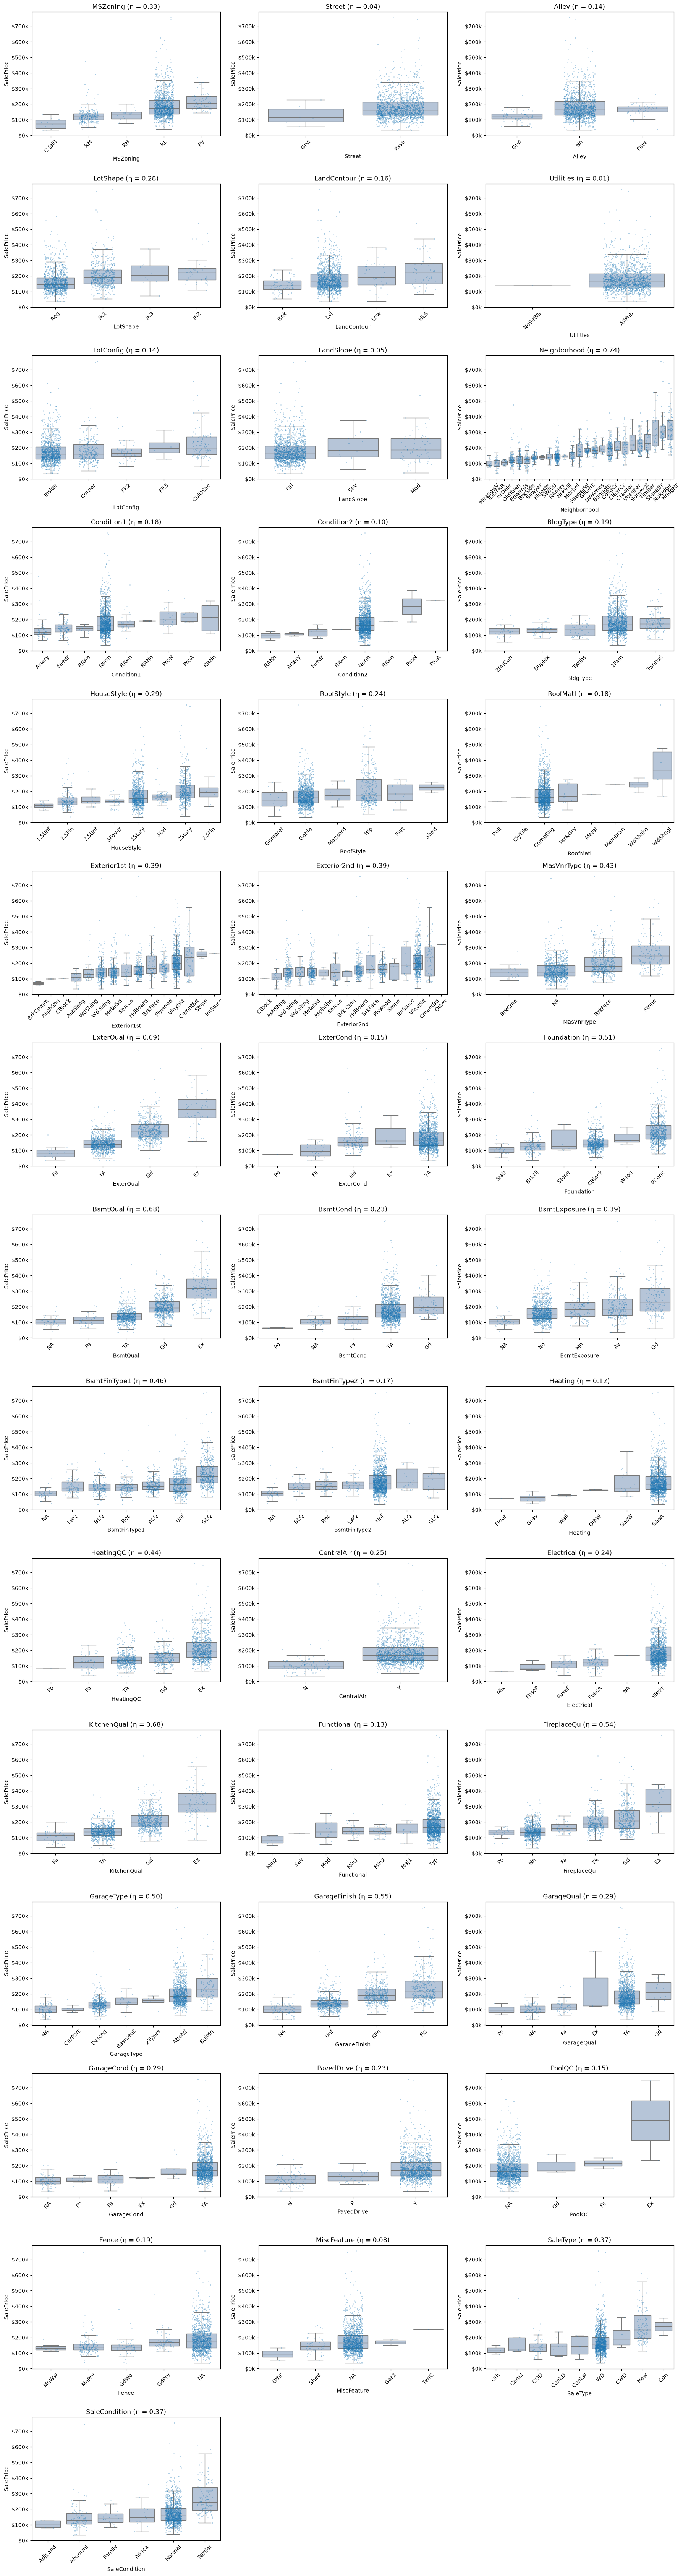

,eta
Neighborhood,0.738630
ExterQual,0.690933
BsmtQual,0.681905
KitchenQual,0.675721
GarageFinish,0.553059
FireplaceQu,0.542181
Foundation,0.506328
GarageType,0.499204
BsmtFinType1,0.459141
HeatingQC,0.442154


In [18]:
def razon_correlacion(categorias, y):
    """Razón de correlación η entre una variable categórica y una numérica."""
    medias = y.groupby(categorias).agg(["mean", "count"])
    var_entre = (medias["count"] * (medias["mean"] - y.mean()) ** 2).sum()
    var_total = ((y - y.mean()) ** 2).sum()
    return np.sqrt(var_entre / var_total)


cat_data = train[cat_cols].fillna("NA")

n_cols = 3
n_rows = int(np.ceil(len(cat_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows))
axes = axes.flatten()

eta_categoricas = {}
for ax, col in zip(axes, cat_cols):
    eta = razon_correlacion(cat_data[col], train["SalePrice"])
    eta_categoricas[col] = eta
    orden = train["SalePrice"].groupby(cat_data[col]).median().sort_values().index
    sns.boxplot(x=cat_data[col], y=train["SalePrice"], order=orden, ax=ax, color="lightsteelblue", showfliers=False)
    sns.stripplot(x=cat_data[col], y=train["SalePrice"], order=orden, ax=ax, color="tab:blue", size=2, alpha=0.4, jitter=0.25)
    ax.set_title(f"{col} (η = {eta:.2f})")
    ax.tick_params(axis="x", labelrotation=45)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y / 1000:,.0f}k"))

# Ocultar los ejes sobrantes de la cuadrícula
for ax in axes[len(cat_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

pd.Series(eta_categoricas, name="eta").sort_values(ascending=False).to_frame()

## Selección de features

Selecciona las 10 variables más relacionadas con `SalePrice` de cada grupo, usando las métricas calculadas arriba:

- **Continuas y discretas:** valor absoluto de la correlación de Pearson |r| (una correlación negativa fuerte también es informativa).
- **Categóricas:** razón de correlación η.

El arreglo `features` reúne las 30 variables que usaremos para construir el modelo.

In [19]:
TOP_N = 10

corr_discretas = train[discretas].corrwith(train["SalePrice"])

top_continuas = pd.Series(corr_continuas).abs().nlargest(TOP_N).index.tolist()
top_discretas = corr_discretas.abs().nlargest(TOP_N).index.tolist()
top_categoricas = pd.Series(eta_categoricas).nlargest(TOP_N).index.tolist()

features = top_continuas + top_discretas + top_categoricas

print(f"Continuas:   {top_continuas}")
print(f"Discretas:   {top_discretas}")
print(f"Categóricas: {top_categoricas}")
print(f"\nTotal features: {len(features)}")

Continuas:   ['GrLivArea', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MasVnrArea', 'BsmtFinSF1', 'LotFrontage']
Discretas:   ['OverallQual', 'GarageCars', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', 'HalfBath', 'BsmtFullBath', 'BedroomAbvGr', 'KitchenAbvGr', 'MSSubClass']
Categóricas: ['Neighborhood', 'ExterQual', 'BsmtQual', 'KitchenQual', 'GarageFinish', 'FireplaceQu', 'Foundation', 'GarageType', 'BsmtFinType1', 'HeatingQC']

Total features: 30
